Matrix Shape: (20, 16)
[[ 0.00000000e+00  1.00000000e+00  0.00000000e+00  1.00000000e+00
   0.00000000e+00  1.00000000e+00  0.00000000e+00  1.00000000e+00
   0.00000000e+00  1.00000000e+00  0.00000000e+00  1.00000000e+00
   0.00000000e+00  1.00000000e+00  0.00000000e+00  1.00000000e+00]
 [ 8.41470985e-01  5.40302306e-01  3.10983593e-01  9.50415280e-01
   9.98334166e-02  9.95004165e-01  3.16175064e-02  9.99500042e-01
   9.99983333e-03  9.99950000e-01  3.16227239e-03  9.99995000e-01
   9.99999833e-04  9.99999500e-01  3.16227761e-04  9.99999950e-01]
 [ 9.09297427e-01 -4.16146837e-01  5.91127117e-01  8.06578410e-01
   1.98669331e-01  9.80066578e-01  6.32033979e-02  9.98000667e-01
   1.99986667e-02  9.99800007e-01  6.32451316e-03  9.99980000e-01
   1.99999867e-03  9.99998000e-01  6.32455490e-04  9.99999800e-01]
 [ 1.41120008e-01 -9.89992497e-01  8.12648897e-01  5.82753611e-01
   2.95520207e-01  9.55336489e-01  9.47260913e-02  9.95503374e-01
   2.99955002e-02  9.99550034e-01  9.48669068e-03 

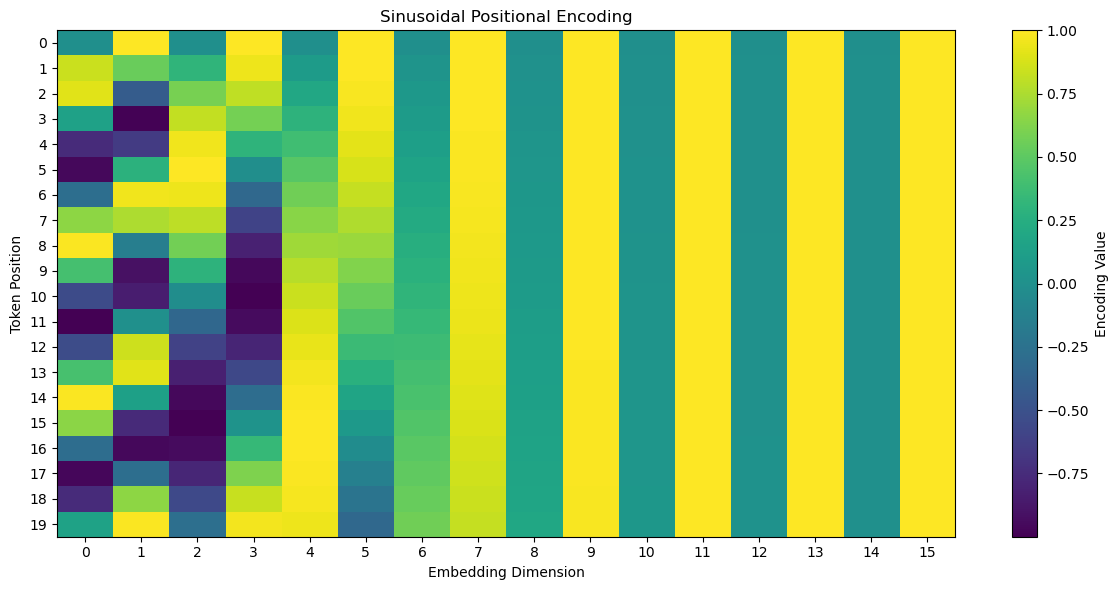

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# Function for sinusoidal positional encoding
def sinusoidal_positional_encoding(seq_len, d_model):

    PE = np.zeros((seq_len, d_model))

    for pos in range(seq_len):
        for i in range(d_model // 2):

            angle = pos / (10000 ** (2 * i / d_model))

            PE[pos, 2 * i] = np.sin(angle)
            PE[pos, 2 * i + 1] = np.cos(angle)

    return PE


# Define parameters
seq_len = 20
d_model = 16

# Generate positional encoding
PE = sinusoidal_positional_encoding(seq_len, d_model)

# Print matrix shape
print("Matrix Shape:", PE.shape)

# Print matrix
print(PE)

# Visualize matrix
plt.figure(figsize=(12, 6))

plt.imshow(PE, aspect='auto', cmap='viridis')

plt.colorbar(label='Encoding Value')

plt.xlabel('Embedding Dimension')
plt.ylabel('Token Position')

plt.title('Sinusoidal Positional Encoding')

plt.xticks(range(d_model))
plt.yticks(range(seq_len))

plt.tight_layout()
plt.show()

In [2]:
import numpy as np
def scaled_dot_product_attention(Q, K, V):

    # Step 1: Calculate dot product of Q and K transpose
    scores = np.matmul(Q, K.T)

    # Step 2: Scale the attention scores
    d_k = K.shape[1]
    scores = scores / np.sqrt(d_k)

    # Step 3: Apply softmax manually (row-wise)
    exp_scores = np.exp(scores - np.max(scores, axis=1, keepdims=True))

    attention_weights = (
        exp_scores / np.sum(exp_scores, axis=1, keepdims=True)
    )

    # Step 4: Calculate final attention output
    output = np.matmul(attention_weights, V)

    return output, attention_weights

# Define Q, K and V matrices
Q = np.array([
    [1, 0],
    [0, 1]
])

K = np.array([
    [1, 0],
    [0, 1]
])

V = np.array([
    [1, 0],
    [0, 1]
])

# Call the attention function
output, attention_weights = scaled_dot_product_attention(Q, K, V)

# Display results
print("Attention Weights:")
print(np.round(attention_weights, 3))

print("\nFinal Attention Output:")
print(np.round(output, 3))

Attention Weights:
[[0.67 0.33]
 [0.33 0.67]]

Final Attention Output:
[[0.67 0.33]
 [0.33 0.67]]


In [3]:
# Verify row-wise sum of attention weights
row_sums = np.sum(attention_weights, axis=1)

print("Sum of each attention row:")
print(row_sums)

# Check whether each row sums to 1
print("\nVerification:")
print(np.allclose(row_sums, 1.0))

Sum of each attention row:
[1. 1.]

Verification:
True


In [4]:
import numpy as np

def self_attention(X, W_Q, W_K, W_V):
    """Compute Q, K, V projections and attention."""

    # Step 1: Compute Query, Key, and Value
    Q = X @ W_Q
    K = X @ W_K
    V = X @ W_V

    # Step 2: Calculate scaled dot-product scores
    d_k = K.shape[1]
    scores = (Q @ K.T) / np.sqrt(d_k)

    # Step 3: Apply row-wise softmax
    scores = scores - np.max(scores, axis=1, keepdims=True)
    attention_weights = np.exp(scores)
    attention_weights /= np.sum(
        attention_weights, axis=1, keepdims=True
    )

    # Step 4: Compute attention output
    output = attention_weights @ V

    return Q, K, V, attention_weights, output

X = np.array([[1, 2], [0, 1]])
W_Q = np.array([[1, 0], [0, 1]])
W_K = np.array([[0, 1], [1, 0]])
W_V = np.array([[2, 0], [0, 1]])

Q, K, V, A, output = self_attention(X, W_Q, W_K, W_V)

print("Query(Q):\n", Q)
print("Key(K):\n", K)
print("Value(V):\n", V)
print("Attention weights:\n", A)
print("Attention output:\n", output)

Query(Q):
 [[1 2]
 [0 1]]
Key(K):
 [[2 1]
 [1 0]]
Value(V):
 [[2 2]
 [0 1]]
Attention weights:
 [[0.8929582  0.1070418 ]
 [0.66976155 0.33023845]]
Attention output:
 [[1.7859164  1.8929582 ]
 [1.3395231  1.66976155]]


In [5]:

import numpy as np

def causal_self_attention(Q, K, V):
    """Return causally masked attention output and weights."""

    # Step 1: Calculate scaled attention scores
    d_k = K.shape[1]
    scores = (Q @ K.T) / np.sqrt(d_k)

    # Step 2: Construct the causal mask manually
    n = Q.shape[0]
    mask = np.triu(np.full((n, n), -np.inf), k=1)

    # Step 3: Apply the mask
    scores = scores + mask

    # Step 4: Apply softmax row-wise
    exp_scores = np.exp(scores - np.max(
        scores, axis=1, keepdims=True
    ))
    weights = exp_scores / np.sum(
        exp_scores, axis=1, keepdims=True
    )

    # Step 5: Calculate the attention output
    output = weights @ V

    return output, weights


# Input matrices
Q = np.array([[1, 0],
              [0, 1],
              [1, 1]], dtype=float)

K = Q.copy()
V = Q.copy()

output, weights = causal_self_attention(Q, K, V)

print("Attention weights:")
print(np.round(weights, 4))

print("\nAttention output:")
print(np.round(output, 4))

Attention weights:
[[1.     0.     0.    ]
 [0.3302 0.6698 0.    ]
 [0.2483 0.2483 0.5035]]

Attention output:
[[1.     0.    ]
 [0.3302 0.6698]
 [0.7517 0.7517]]


In [6]:

import numpy as np

def cross_attention(decoder_states, encoder_states,
                    W_Q, W_K, W_V):
    """Return cross-attention outputs and weights."""

    # 1. Generate query, key, and value matrices
    Q = decoder_states @ W_Q
    K = encoder_states @ W_K
    V = encoder_states @ W_V

    # 2. Calculate scaled attention scores
    d_k = K.shape[1]
    scores = (Q @ K.T) / np.sqrt(d_k)

    # 3. Apply softmax row-wise
    exp_scores = np.exp(
        scores - np.max(scores, axis=1, keepdims=True)
    )
    weights = exp_scores / np.sum(
        exp_scores, axis=1, keepdims=True
    )

    # 4. Calculate weighted encoder information
    output = weights @ V

    return output, weights


# Example using the question's Q, K and V directly
Q = np.array([[1, 0]], dtype=float)

K = np.array([[1, 0],
              [0, 1],
              [1, 1]], dtype=float)

V = np.array([[2, 0],
              [0, 2],
              [1, 1]], dtype=float)

# Identity projections preserve the given matrices
W_Q = np.eye(2)
W_K = np.eye(2)
W_V = np.eye(2)

# Q is already projected, so pass it as decoder states.
# K and V share encoder states; use identity projections.
# Here, the same encoder states cannot represent both K and V,
# so use the projected calculation directly for this example.

scores = (Q @ K.T) / np.sqrt(K.shape[1])
exp_scores = np.exp(scores - np.max(scores, axis=1, keepdims=True))
weights = exp_scores / np.sum(exp_scores, axis=1, keepdims=True)
output = weights @ V

print("Attention weights:")
print(np.round(weights, 4))

print("Cross-attention output:")
print(np.round(output, 4))

Attention weights:
[[0.4011 0.1978 0.4011]]
Cross-attention output:
[[1.2033 0.7967]]


In [7]:
import numpy as np

def multi_head_attention(x, W_Q, W_K, W_V, W_O, num_heads):

    seq_len, d_model = x.shape
    d_k = d_model // num_heads

    # Project input into Q, K and V
    Q = x @ W_Q
    K = x @ W_K
    V = x @ W_V

    heads = []
    weights = []

    # Compute attention independently for each head
    for h in range(num_heads):

        start = h * d_k
        end = (h + 1) * d_k

        # Split into individual heads
        q = Q[:, start:end]
        k = K[:, start:end]
        v = V[:, start:end]

        # Scaled dot-product attention
        scores = (q @ k.T) / np.sqrt(d_k)

        # Softmax
        exp_scores = np.exp(
            scores - np.max(scores, axis=-1, keepdims=True)
        )
        attn = exp_scores / np.sum(
            exp_scores, axis=-1, keepdims=True
        )

        # Head output
        head_output = attn @ v

        heads.append(head_output)
        weights.append(attn)

    # Concatenate all heads
    concat = np.concatenate(heads, axis=-1)

    # Final output projection
    output = concat @ W_O

    # Return output and attention weights
    return output, np.array(weights)

In [8]:

import numpy as np

def stable_softmax(x, axis=-1):
    """Numerically stable NumPy softmax."""

    # Subtract maximum value
    x_shifted = x - np.max(
        x, axis=axis, keepdims=True
    )

    # Calculate exponentials
    exp_x = np.exp(x_shifted)

    # Normalize probabilities
    return exp_x / np.sum(
        exp_x, axis=axis, keepdims=True
    )


# Test input
x = np.array([1000, 1001, 1002])

# Stable softmax
stable_result = stable_softmax(x)

# Direct exponentiation
direct_result = np.exp(x) / np.sum(np.exp(x))

print("Stable Softmax:", stable_result)
print("Direct Softmax:", direct_result)

Stable Softmax: [0.09003057 0.24472847 0.66524096]
Direct Softmax: [nan nan nan]


C:\Users\User\AppData\Local\Temp\ipykernel_11156\2108487377.py:27: RuntimeWarning: overflow encountered in exp
  direct_result = np.exp(x) / np.sum(np.exp(x))
C:\Users\User\AppData\Local\Temp\ipykernel_11156\2108487377.py:27: RuntimeWarning: invalid value encountered in divide
  direct_result = np.exp(x) / np.sum(np.exp(x))


Temperature: 0.5
Attention weights: [0.01587624 0.11731043 0.86681333]
Temperature: 1
Attention weights: [0.09003057 0.24472847 0.66524096]
Temperature: 2
Attention weights: [0.18632372 0.30719589 0.50648039]
Temperature: 4
Attention weights: [0.25427521 0.32649584 0.41922895]


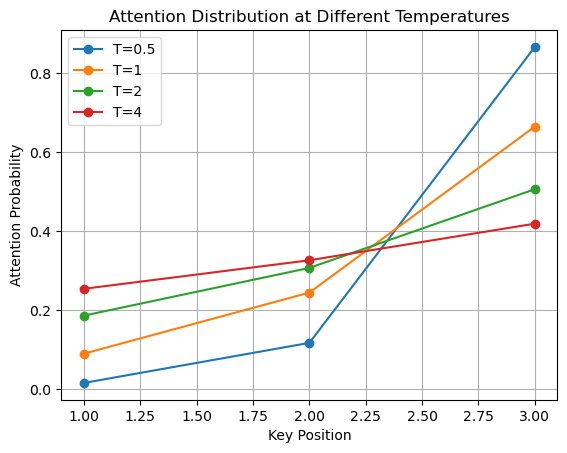

In [9]:

import numpy as np
import matplotlib.pyplot as plt

scores = np.array([1, 2, 3])
temperatures = [0.5, 1, 2, 4]

for T in temperatures:

    # Scale scores by temperature
    scaled = scores / T

    # Stable softmax
    exp_scores = np.exp(
        scaled - np.max(scaled)
    )

    weights = exp_scores / np.sum(exp_scores)

    print("Temperature:", T)
    print("Attention weights:", weights)

    plt.plot(
        range(1, 4),
        weights,
        marker='o',
        label=f"T={T}"
    )

plt.xlabel("Key Position")
plt.ylabel("Attention Probability")
plt.title("Attention Distribution at Different Temperatures")
plt.legend()
plt.grid()
plt.show()

In [10]:

import numpy as np

# 1. Layer Normalization
def layer_norm(X, gamma, beta, eps=1e-5):

    # Mean and variance across features
    mean = np.mean(X, axis=-1, keepdims=True)

    var = np.var(X, axis=-1, keepdims=True)

    # Normalize
    X_norm = (X - mean) / np.sqrt(var + eps)

    # Scale and shift
    return gamma * X_norm + beta


# 2. Feed Forward Network
def feed_forward(X, W1, b1, W2, b2):

    # First linear transformation
    hidden = X @ W1 + b1

    # ReLU activation
    hidden = np.maximum(0, hidden)

    # Second linear transformation
    output = hidden @ W2 + b2

    return output


# 3. Transformer Encoder Block
def transformer_encoder_block(X, params):
    """
    Return (seq_len, d_model) output.
    Assumes multi_head_attention() from Question 6
    is already defined.
    """

    # Multi-head self-attention
    attn_output, weights = multi_head_attention(
        X,
        params["W_Q"],
        params["W_K"],
        params["W_V"],
        params["W_O"],
        params["num_heads"]
    )

    # Residual connection + Layer Normalization
    H = layer_norm(
        X + attn_output,
        params["gamma1"],
        params["beta1"]
    )

    # Feed Forward Network
    ffn_output = feed_forward(
        H,
        params["W1"],
        params["b1"],
        params["W2"],
        params["b2"]
    )

    # Residual connection + Layer Normalization
    Y = layer_norm(
        H + ffn_output,
        params["gamma2"],
        params["beta2"]
    )

    return Y

In [11]:
import numpy as np

# Stable softmax
def stable_softmax(x, axis=-1):
    x = x - np.max(x, axis=axis, keepdims=True)
    exp_x = np.exp(x)
    return exp_x / np.sum(exp_x, axis=axis, keepdims=True)


# Layer Normalization
def layer_norm(X, gamma, beta, eps=1e-5):
    mean = np.mean(X, axis=-1, keepdims=True)
    var = np.var(X, axis=-1, keepdims=True)

    X_norm = (X - mean) / np.sqrt(var + eps)

    return gamma * X_norm + beta


# Generalized Multi-Head Attention
# Supports self-attention and cross-attention
def multi_head_attention(query, context,
                         W_Q, W_K, W_V, W_O,
                         num_heads, causal=False):

    seq_q, d_model = query.shape
    seq_k = context.shape[0]

    d_k = d_model // num_heads

    # Project Q, K and V
    Q = query @ W_Q
    K = context @ W_K
    V = context @ W_V

    # Split into heads
    Q = Q.reshape(seq_q, num_heads, d_k).transpose(1, 0, 2)
    K = K.reshape(seq_k, num_heads, d_k).transpose(1, 0, 2)
    V = V.reshape(seq_k, num_heads, d_k).transpose(1, 0, 2)

    # Scaled dot-product attention
    scores = (Q @ K.transpose(0, 2, 1)) / np.sqrt(d_k)

    # Causal mask for decoder self-attention
    if causal:
        mask = np.triu(
            np.ones((seq_q, seq_k), dtype=bool),
            k=1
        )
        scores = np.where(mask[None, :, :], -np.inf, scores)

    # Attention weights
    weights = stable_softmax(scores, axis=-1)

    # Weighted values
    output = weights @ V

    # Combine heads
    output = output.transpose(1, 0, 2)
    output = output.reshape(seq_q, d_model)

    # Output projection
    output = output @ W_O

    return output, weights


# Feed Forward Network
def feed_forward(X, W1, b1, W2, b2):

    hidden = X @ W1 + b1
    hidden = np.maximum(0, hidden)  # ReLU

    return hidden @ W2 + b2


# Transformer Decoder Block
def transformer_decoder_block(decoder_input,
                               encoder_output,
                               params):
    """
    Return decoder output after masked attention,
    cross-attention and feed-forward layers.
    """

    h = params["num_heads"]

    # 1. Masked self-attention
    self_attn, self_weights = multi_head_attention(
        decoder_input,
        decoder_input,
        params["WQ_self"],
        params["WK_self"],
        params["WV_self"],
        params["WO_self"],
        h,
        causal=True
    )

    # 2. Residual + Layer Normalization
    H1 = layer_norm(
        decoder_input + self_attn,
        params["gamma1"],
        params["beta1"]
    )

    # 3. Cross-attention
    cross_attn, cross_weights = multi_head_attention(
        H1,
        encoder_output,
        params["WQ_cross"],
        params["WK_cross"],
        params["WV_cross"],
        params["WO_cross"],
        h,
        causal=False
    )

    # 4. Residual + Layer Normalization
    H2 = layer_norm(
        H1 + cross_attn,
        params["gamma2"],
        params["beta2"]
    )

    # 5. Feed Forward Network
    ffn = feed_forward(
        H2,
        params["W1"],
        params["b1"],
        params["W2"],
        params["b2"]
    )

    # 6. Residual + Layer Normalization
    Y = layer_norm(
        H2 + ffn,
        params["gamma3"],
        params["beta3"]
    )

    return Y, self_weights, cross_weights


# -------------------------------
# Testing and dimension verification
# -------------------------------

np.random.seed(42)

d_model = 8
num_heads = 2
d_ff = 16

encoder_len = 5
decoder_len = 3

# Encoder and decoder inputs
encoder_output = np.random.randn(encoder_len, d_model)
decoder_input = np.random.randn(decoder_len, d_model)

# Initialize parameters
params = {
    "num_heads": num_heads,

    "WQ_self": np.random.randn(8, 8) * 0.1,
    "WK_self": np.random.randn(8, 8) * 0.1,
    "WV_self": np.random.randn(8, 8) * 0.1,
    "WO_self": np.random.randn(8, 8) * 0.1,

    "WQ_cross": np.random.randn(8, 8) * 0.1,
    "WK_cross": np.random.randn(8, 8) * 0.1,
    "WV_cross": np.random.randn(8, 8) * 0.1,
    "WO_cross": np.random.randn(8, 8) * 0.1,

    "W1": np.random.randn(8, d_ff) * 0.1,
    "b1": np.zeros(d_ff),
    "W2": np.random.randn(d_ff, 8) * 0.1,
    "b2": np.zeros(8),

    "gamma1": np.ones(8),
    "beta1": np.zeros(8),

    "gamma2": np.ones(8),
    "beta2": np.zeros(8),

    "gamma3": np.ones(8),
    "beta3": np.zeros(8)
}

# Run decoder block
Y, self_weights, cross_weights = transformer_decoder_block(
    decoder_input,
    encoder_output,
    params
)

# Verify dimensions
print("Encoder output:", encoder_output.shape)
print("Decoder input:", decoder_input.shape)
print("Self-attention weights:", self_weights.shape)
print("Cross-attention weights:", cross_weights.shape)
print("Final decoder output:", Y.shape)

Encoder output: (5, 8)
Decoder input: (3, 8)
Self-attention weights: (2, 3, 3)
Cross-attention weights: (2, 3, 5)
Final decoder output: (3, 8)


Sequence length: 32
Execution time: 0.00023858000058680774 seconds
Attention memory: 0.015625 MB
--------------------------
Sequence length: 64
Execution time: 0.0009972999978344887 seconds
Attention memory: 0.0625 MB
--------------------------
Sequence length: 128
Execution time: 0.0035138900042511524 seconds
Attention memory: 0.25 MB
--------------------------
Sequence length: 256
Execution time: 0.007647470000665635 seconds
Attention memory: 1.0 MB
--------------------------
Sequence length: 512
Execution time: 0.0291751499986276 seconds
Attention memory: 4.0 MB
--------------------------


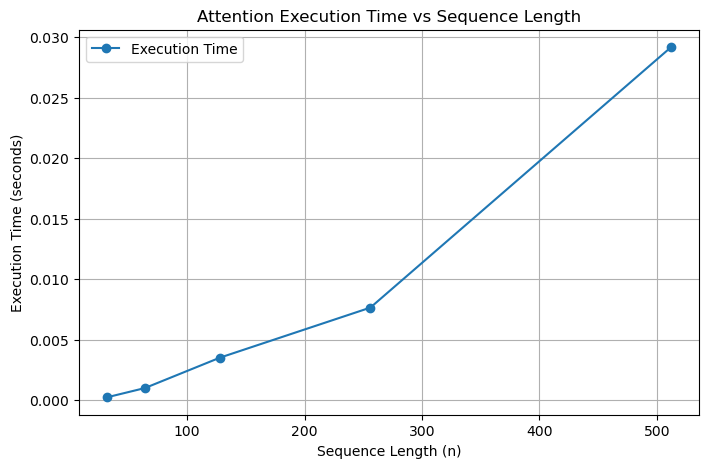

In [12]:
import numpy as np
import time
import matplotlib.pyplot as plt


def stable_softmax(x, axis=-1):
    x = x - np.max(x, axis=axis, keepdims=True)
    exp_x = np.exp(x)
    return exp_x / np.sum(exp_x, axis=axis, keepdims=True)


def benchmark_attention(seq_lengths, d_model, num_heads):

    d_k = d_model // num_heads

    times = []
    memories = []

    for n in seq_lengths:

        # Generate random Q, K, V
        Q = np.random.randn(
            num_heads, n, d_k
        ).astype(np.float32)

        K = np.random.randn(
            num_heads, n, d_k
        ).astype(np.float32)

        V = np.random.randn(
            num_heads, n, d_k
        ).astype(np.float32)

        # Benchmark attention computation
        def run_attention():

            scores = np.matmul(
                Q, K.transpose(0, 2, 1)
            ) / np.sqrt(d_k)

            weights = stable_softmax(scores)

            output = np.matmul(weights, V)

            return output

        # Warm-up
        run_attention()

        # Measure execution time
        repetitions = 10

        start = time.perf_counter()

        for _ in range(repetitions):
            run_attention()

        end = time.perf_counter()

        avg_time = (end - start) / repetitions

        # Theoretical attention matrix memory
        memory_bytes = (
            num_heads * n * n * 4
        )

        memory_mb = memory_bytes / (1024 ** 2)

        times.append(avg_time)
        memories.append(memory_mb)

        print("Sequence length:", n)
        print("Execution time:", avg_time, "seconds")
        print("Attention memory:", memory_mb, "MB")
        print("--------------------------")

    # Plot execution time
    plt.figure(figsize=(8, 5))

    plt.plot(
        seq_lengths,
        times,
        marker='o',
        label='Execution Time'
    )

    plt.xlabel("Sequence Length (n)")
    plt.ylabel("Execution Time (seconds)")
    plt.title("Attention Execution Time vs Sequence Length")
    plt.grid()
    plt.legend()
    plt.show()

    return times, memories


# Experiment
seq_lengths = [32, 64, 128, 256, 512]

times, memories = benchmark_attention(
    seq_lengths,
    d_model=64,
    num_heads=4
)